# Fig. 5 — energy, force and axion angle along the axion-active patterns (paper `main2.tex`, `fig:harmonic`)

Y₂Ir₂O₇, the three Γ₂⁻ basis patterns (1: Y, 2: Ir, 3: O 48f), Q = 0.01, 0.02, 0.03, 0.05 Å per Cartesian component of the
raw SMODES vector v (entries ±1), all SCFs at conv_thr 1e-10 (log 2026-10-17).

* **(a)** ΔE(Q) = E(Q) − E(0) (filled) and −½ Q v·[F(Q) − F(0)] (open), which agree for a harmonic energy; curve ½kQ² + a₄Q⁴
  fitted to the energies. Γ₂⁻ is odd under inversion, a symmetry of the undistorted crystal, so ΔE(−Q) = ΔE(Q): the
  Q < 0 points are the reflections.
* **(b)** θ(Q) = θ_CS(displaced) − θ_CS(undistorted) from the Chern–Simons 3-form (points; nk 12; job 214446;
  θ_CS(undistorted) = 9e-11), against the line Q·∂θ/∂Q|₀ with the four-curvature slope (the value in the tables). θ is odd
  under inversion: θ(−Q) = −θ(Q).
* **(c)** The validation: θ(Q)/Q divided by the four-curvature slope. θ(Q)/Q = ∂θ/∂Q|₀ + O(Q²), so its Q → 0 intercept
  (fit a + bQ² + cQ⁴, curves) is an independent estimate of the slope; the curves reach 1 at Q = 0 to ≤ 0.04%, and their
  departure from 1 is θ's nonlinearity (0.6 / 3.1 / 1.6% at 0.05 Å).

The four-curvature slope at Q → 0 is computed here from the two endpoint estimates at each Q (`nk_10.npz` of each pair,
self-test base 214249, series windows), each end fitted to a + bQ² (pattern 2: + cQ⁴) and the two limits averaged,
as in log 10-17 "YIO self-test base: all modes". MnBi₂Te₄ θ(Q) does not exist yet (only Q = 0.01 and 0.03 Å Wannier
pairs, chain running), so the MBT panel of the placeholder is not drawn.

In [1]:
# ---- settings
from pathlib import Path
ROOT = Path("/Users/treycole/Repos/axion-phonon")
DATA = ROOT / "data"
BASE_SCF = DATA / "Y2Ir2O7/base/lda/scf_conv1e-10_213998"                              # E(0), F(0); 1e-10
SCF = {   # pattern: {Q (Å): SCF folder at conv_thr 1e-10}
    1: {0.01: "mode1/Q_0.01A/lda/scf_nscf_conv1e-10_213999", 0.02: "mode1/Q_0.02A/lda/scf_nscf_conv1e-10_214000",
        0.03: "mode1/Q_0.03A/lda/scf_nscf_conv1e-10_214001", 0.05: "mode1/Q_0.05A/lda/scf_nscf_conv1e-10_214002"},
    2: {0.01: "mode2/Q_0.01A/lda/scf_nscf_conv1e-10_214003", 0.02: "mode2/Q_0.02A/lda/scf_nscf_conv1e-10_214004",
        0.03: "mode2/Q_0.03A/lda/scf_nscf_conv1e-10_214005", 0.05: "mode2/Q_0.05A/lda/scf_nscf_conv1e-10_214015"},
    3: {0.01: "mode3/Q_0.01A/lda/scf_nscf_conv1e-10_214016", 0.02: "mode3/Q_0.02A/lda/scf_nscf_conv1e-10_214011",
        0.03: "mode3/Q_0.03A/lda/scf_nscf_conv1e-10_214012", 0.05: "mode3/Q_0.05A/lda/scf_nscf_conv1e-10_214013"},
}
SCF_ROOT = DATA / "Y2Ir2O7/phonon/GM2-"
C2_GLOB = "mode{m}/Q_{q:.2f}A/lda/w90_trial02_ampwin10_2026-10-18_*/nk_sweep_tif_shared_ws_selftestbase_pinned/nk_10.npz"   # four-curvature, both ends; atom-pinned (= centres to 2e-6)
C2_FIT_DEGREE = {1: 1, 2: 2, 3: 1}           # per pattern: fit each end to a + bQ² (1) or a + bQ² + cQ⁴ (2) in Q²
THETA_Q = ROOT / "archive/diagnostics/2026-10-26_yio_pinned/theta_Q.npz"   # 3-form θ(Q), assemble_pinned.py
THETA_NK = 12                                # 10 or 12 (identical to 1e-6)
THETA_FIT_DEGREE = 2                         # θ/Q = a + bQ² + cQ⁴ (2) or a + bQ² (1)
LABELS = {1: "Y", 2: "Ir", 3: r"O$_{48f}$"}
COLORS = {1: "C0", 2: "C3", 3: "C2"}
NAT = 22
FIGSIZE = (3.4, 5.6)                         # inches; 3.4 = one column
FONT_SIZE = 8
SAVE_FIG = ROOT / "paper/figures/fig5.pdf"   # or None
# ---------------

In [2]:
# ---- data: energies and forces, four-curvature slopes, 3-form θ(Q)
import re
import numpy as np
import matplotlib.pyplot as plt

RY_EV, RYBOHR_EVA = 13.605693, 13.605693 / 0.529177

def positions(folder):
    t = (folder / "Y2Ir2O7.scf.in").read_text()
    rows = [line.split() for line in t.split("ATOMIC_POSITIONS angstrom")[1].strip().splitlines()[:NAT]]
    return np.array([[float(x) for x in r[1:4]] for r in rows])

def energy_forces(folder):
    t = (folder / "Y2Ir2O7.scf.out").read_text()
    E = float(re.findall(r"!\s+total energy\s+=\s+(\S+)", t)[-1]) * RY_EV
    F = np.array(re.findall(r"atom\s+\d+ type\s+\d+\s+force =\s+(\S+)\s+(\S+)\s+(\S+)", t), float)[:NAT] * RYBOHR_EVA
    return E, F

R0 = positions(BASE_SCF)
E0, F0 = energy_forces(BASE_SCF)
energy = {}                                  # pattern: (Q, ΔE, −½ Q v·ΔF) arrays
for m, runs in SCF.items():
    rows = []
    for q, sub in sorted(runs.items()):
        folder = SCF_ROOT / sub
        v = (positions(folder) - R0) / q
        E, F = energy_forces(folder)
        rows.append((q, E - E0, -0.5 * q * float((v * (F - F0)).sum())))
    energy[m] = np.array(rows).T
    print(f"pattern {m}: ΔE / (−½Q v·ΔF) − 1 = {np.round(100 * (energy[m][1] / energy[m][2] - 1), 2)} %")

slope = {}                                   # pattern: four-curvature ∂θ/∂Q at Q -> 0 (mean of the two ends' limits)
for m in SCF:
    qs = np.array(sorted(SCF[m]))
    ends = np.array([np.load(next(SCF_ROOT.glob(C2_GLOB.format(m=m, q=q))), allow_pickle=True)["dtheta"].real for q in qs])
    limits = [np.polyfit(qs ** 2, ends[:, e], C2_FIT_DEGREE[m])[-1] for e in (0, 1)]
    slope[m] = float(np.mean(limits))
    print(f"pattern {m}: four-curvature ends at Q -> 0 {limits[0]:+.6f} / {limits[1]:+.6f}, slope {slope[m]:+.6f} rad/Å")

z = np.load(THETA_Q)
theta = {m: np.array([(k[1], v[1]) for k, v in zip(z["keys"], z["values"]) if k[0] == m and k[2] == THETA_NK]).T for m in SCF}
intercept = {}
for m, (qs, th) in theta.items():
    coef = np.polyfit(qs ** 2, th / qs, THETA_FIT_DEGREE)
    intercept[m] = coef
    print(f"pattern {m}: 3-form intercept {coef[-1]:+.6f} rad/Å vs four-curvature {slope[m]:+.6f} "
          f"({100 * (coef[-1] / slope[m] - 1):+.3f}%); θ/(Q·slope) − 1 at {qs[-1]} Å: {100 * (th[-1] / qs[-1] / slope[m] - 1):+.2f}%")

pattern 1: ΔE / (−½Q v·ΔF) − 1 = [-0.3  -0.15 -0.29 -0.74] %
pattern 2: ΔE / (−½Q v·ΔF) − 1 = [-0.03  0.21  0.32  0.76] %
pattern 3: ΔE / (−½Q v·ΔF) − 1 = [0.44 0.2  0.12 0.07] %
pattern 1: four-curvature ends at Q -> 0 -0.017152 / -0.017139, slope -0.017145 rad/Å
pattern 2: four-curvature ends at Q -> 0 +0.054738 / +0.054737, slope +0.054737 rad/Å
pattern 3: four-curvature ends at Q -> 0 +0.063763 / +0.063769, slope +0.063766 rad/Å
pattern 1: 3-form intercept -0.017144 rad/Å vs four-curvature -0.017145 (-0.008%); θ/(Q·slope) − 1 at 0.05 Å: +0.55%
pattern 2: 3-form intercept +0.054737 rad/Å vs four-curvature +0.054737 (-0.000%); θ/(Q·slope) − 1 at 0.05 Å: -3.10%
pattern 3: 3-form intercept +0.063791 rad/Å vs four-curvature +0.063766 (+0.039%); θ/(Q·slope) − 1 at 0.05 Å: -1.58%


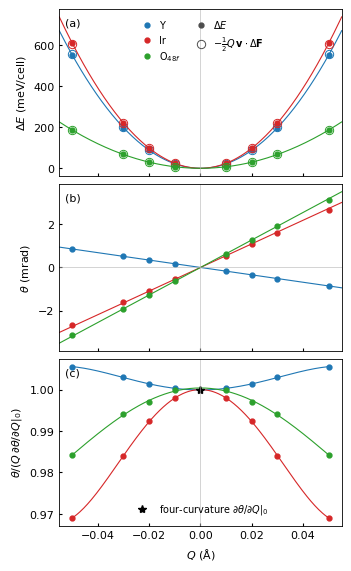

In [3]:
# ---- draw
plt.rcParams.update({"font.size": FONT_SIZE, "axes.linewidth": 0.6})
fig, (ax_e, ax_t, ax_r) = plt.subplots(3, 1, figsize=FIGSIZE, sharex=True, layout="constrained")
q = np.linspace(-0.055, 0.055, 221)
for m in SCF:
    c = COLORS[m]
    Q, dE, dEf = energy[m]
    k, a4 = np.linalg.lstsq(np.c_[0.5 * Q ** 2, Q ** 4], dE, rcond=None)[0]
    ax_e.plot(q, 1e3 * (0.5 * k * q ** 2 + a4 * q ** 4), color=c, lw=0.8)
    ax_e.plot(np.r_[-Q, Q], 1e3 * np.r_[dE, dE], "o", ms=3.5, color=c, label=LABELS[m])
    ax_e.plot(np.r_[-Q, Q], 1e3 * np.r_[dEf, dEf], "o", ms=6, mfc="none", mew=0.7, color=c)

    qs, th = theta[m]
    ax_t.plot(q, 1e3 * q * slope[m], color=c, lw=0.8)
    ax_t.plot(np.r_[-qs, qs], 1e3 * np.r_[-th, th], "o", ms=3.5, color=c, label=LABELS[m])

    q_fit = q[np.abs(q) <= qs.max()]                       # the fit only where there are data
    ax_r.plot(q_fit, np.polyval(intercept[m], q_fit ** 2) / slope[m], color=c, lw=0.8)
    ax_r.plot(np.r_[-qs, qs], np.r_[th / qs, th / qs] / slope[m], "o", ms=3.5, color=c)
ax_r.plot([0], [1], "k*", ms=6, label=r"four-curvature $\partial\theta/\partial Q|_0$")
ax_e.plot([], [], "o", ms=3.5, color="0.3", label=r"$\Delta E$")
ax_e.plot([], [], "o", ms=6, mfc="none", mew=0.7, color="0.3", label=r"$-\frac{1}{2}Q\,\mathbf{v}\cdot\Delta\mathbf{F}$")
ax_e.legend(fontsize=FONT_SIZE - 1, ncol=2, frameon=False, loc="upper center", handletextpad=0.3, columnspacing=1.0)
ax_r.legend(fontsize=FONT_SIZE - 1, frameon=False, loc="lower center")
ax_e.set_ylabel(r"$\Delta E$ (meV/cell)")
ax_t.set_ylabel(r"$\theta$ (mrad)")
ax_r.set_ylabel(r"$\theta / (Q\,\partial\theta/\partial Q|_0)$")
ax_r.set_xlabel(r"$Q$ (Å)")
for ax, tag in zip((ax_e, ax_t, ax_r), "abc"):
    ax.axvline(0, color="0.7", lw=0.4)
    ax.tick_params(direction="in", length=2, which="both")
    ax.text(0.02, 0.95, f"({tag})", transform=ax.transAxes, va="top", fontsize=FONT_SIZE)
ax_t.axhline(0, color="0.7", lw=0.4)
ax_r.set_xlim(q[0], q[-1])
if SAVE_FIG:
    SAVE_FIG.parent.mkdir(exist_ok=True)
    fig.savefig(SAVE_FIG)
    fig.savefig(SAVE_FIG.with_suffix(".png"), dpi=300)
plt.show()
plt.rcdefaults()